# MLB Prospects 2026: MLB Readiness Analysis
This notebook compares historical top-20 prospects (2017–2025) against the 2026 top-20 prospects to predict which 2026 prospects are likely to appear in the MLB during the 2026 season.

**Methodology:**
- Extract stats for all historical prospects who DID make the MLB
- Build benchmark thresholds from their pre-MLB stats
- Score each 2026 prospect against those benchmarks
- Output a readiness verdict for each 2026 prospect

## 1. Setup & Load Data

In [3]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Load the Excel file — update path if needed
FILE_PATH = './data/mlb_prospects_data.xlsx'

xl = pd.ExcelFile(FILE_PATH)
print('Sheets found:', xl.sheet_names)

Sheets found: ['2026', '2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017']


## 2. Parse All Hitter & Pitcher Data by Year

In [5]:
import pandas as pd
import numpy as np
import re

years = list(range(2017, 2027))

def clean_col_name(x):
    if pd.isna(x):
        return "Unnamed"
    x = str(x).strip()
    x = re.sub(r"\s+", " ", x)
    return x if x else "Unnamed"

def make_unique_columns(cols):
    seen = {}
    out = []
    for col in cols:
        col = clean_col_name(col)
        if col in seen:
            seen[col] += 1
            out.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            out.append(col)
    return out

def normalize_block(df_block, year, player_type):
    df_block = df_block.copy()

    df_block.columns = make_unique_columns(df_block.columns)

    df_block = df_block.dropna(axis=0, how='all').dropna(axis=1, how='all')

    if len(df_block) == 0:
        return pd.DataFrame()

    first_col = df_block.columns[0]

    df_block = df_block[
        df_block[first_col].astype(str).str.strip().str.lower()
        != first_col.strip().lower()
    ]

    df_block = df_block.reset_index(drop=True)
    df_block["Source_Year"] = year
    df_block["Player_Type"] = player_type

    return df_block

def split_sheet_into_hitters_pitchers(sheet_df, year):
    temp = sheet_df.copy()
    temp = temp.dropna(axis=0, how='all').dropna(axis=1, how='all')
    temp = temp.reset_index(drop=True)

    marker_rows = []
    for i in range(len(temp)):
        row_text = " | ".join(temp.iloc[i].fillna("").astype(str).str.lower().tolist())
        if "hitter" in row_text or "batter" in row_text:
            marker_rows.append((i, "hitters"))
        elif "pitcher" in row_text:
            marker_rows.append((i, "pitchers"))

    hitters_df = pd.DataFrame()
    pitchers_df = pd.DataFrame()

    if len(marker_rows) >= 2:
        for idx, (start_row, kind) in enumerate(marker_rows):
            end_row = marker_rows[idx + 1][0] if idx + 1 < len(marker_rows) else len(temp)

            if start_row + 1 >= end_row:
                continue

            header = temp.iloc[start_row + 1].tolist()
            block = temp.iloc[start_row + 2:end_row].copy()
            block.columns = header
            block = normalize_block(block, year, kind)

            if kind == "hitters":
                hitters_df = block
            elif kind == "pitchers":
                pitchers_df = block

    else:
        cols_lower = [str(c).lower() for c in temp.columns]
        if any(x in " ".join(cols_lower) for x in ["avg", "obp", "slg", "ops"]):
            hitters_df = normalize_block(temp, year, "hitters")
        elif any(x in " ".join(cols_lower) for x in ["era", "whip", "fip"]):
            pitchers_df = normalize_block(temp, year, "pitchers")

    return hitters_df, pitchers_df

all_hitters = []
all_pitchers = []

for yr in years:
    try:
        sheet = pd.read_excel(FILE_PATH, sheet_name=str(yr), header=None)
    except Exception as e:
        print(f"Could not read sheet {yr}: {e}")
        continue

    h, p = split_sheet_into_hitters_pitchers(sheet, yr)

    if not h.empty:
        all_hitters.append(h)
    if not p.empty:
        all_pitchers.append(p)

    print(f"{yr}: {len(h)} hitters, {len(p)} pitchers")

hitters_df = pd.concat(all_hitters, ignore_index=True, sort=False) if all_hitters else pd.DataFrame()
pitchers_df = pd.concat(all_pitchers, ignore_index=True, sort=False) if all_pitchers else pd.DataFrame()

print(f"\nTotal hitters: {len(hitters_df)}, Total pitchers: {len(pitchers_df)}")
print("\nHitters columns:")
print(hitters_df.columns.tolist())
print("\nPitchers columns:")
print(pitchers_df.columns.tolist())

2017: 15 hitters, 5 pitchers
2018: 14 hitters, 6 pitchers
2019: 18 hitters, 2 pitchers
2020: 10 hitters, 10 pitchers
2021: 16 hitters, 4 pitchers
2022: 16 hitters, 4 pitchers
2023: 18 hitters, 2 pitchers
2024: 15 hitters, 5 pitchers
2025: 13 hitters, 7 pitchers
2026: 13 hitters, 7 pitchers

Total hitters: 148, Total pitchers: 52

Hitters columns:
['Top 100', 'Org Rk', 'Year', 'Name', 'Org', 'Pos', 'Current Level', 'ETA', 'FV', 'Age', 'Ht', 'Wt', 'B', 'T', 'Sign Yr', 'Sign Mkt', 'G', 'PA', 'AB', 'R', 'H', '2B', '3B', 'HR', 'RBI', 'SB', 'CS', 'BB', 'SO', 'AVG', 'OBP', 'SLG', 'OPS', 'Stats_Source', 'Source_Year', 'Player_Type', 'Risk', 'Sign Org', 'Bonus', 'Signed From', 'Unnamed_5', 'Unnamed_6']

Pitchers columns:
['Top 100', 'Org Rk', 'Year', 'Name', 'Org', 'Pos', 'Current Level', 'ETA', 'FV', 'Age', 'Ht', 'Wt', 'B', 'T', 'Sign Yr', 'Sign Mkt', 'W', 'L', 'W-L%', 'ERA', 'G', 'GS', 'GF', 'CG', 'SHO', 'SV', 'IP', 'H', 'R', 'ER', 'HR', 'BB', 'SO', 'HBP', 'WP', 'BF', 'ERA+', 'FIP', 'WHIP', '

## 3. Clean & Type-Cast Stats

In [7]:
HITTER_NUM = ['AVG', 'OBP', 'SLG', 'OPS', 'HR', 'BB', 'SO', 'PA', 'G', 'SB', 'RBI', 'FV', 'Age']
PITCHER_NUM = ['ERA', 'WHIP', 'FIP', 'SO', 'BB', 'IP', 'G', 'GS', 'ERA+', 'FV', 'Age']

def cast_numeric(df, cols):
    for c in cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

hitters_df = cast_numeric(hitters_df, HITTER_NUM)
pitchers_df = cast_numeric(pitchers_df, PITCHER_NUM)

# Normalise 'Current Level' and 'Stats_Source'
def is_spring_or_minor(src, level):
    """Return True if stats are from spring training or minor leagues."""
    src_str = str(src).lower()
    lvl_str = str(level).upper()
    return ('spring' in src_str or
            'minor' in src_str or
            lvl_str in ['A', 'A+', 'AA', 'AAA', 'ST', 'R'])

if 'Stats_Source' in hitters_df.columns and 'Current Level' in hitters_df.columns:
    hitters_df['Is_Pre_MLB'] = hitters_df.apply(
        lambda r: is_spring_or_minor(r.get('Stats_Source', ''), r.get('Current Level', '')), axis=1
    )
if 'Stats_Source' in pitchers_df.columns and 'Current Level' in pitchers_df.columns:
    pitchers_df['Is_Pre_MLB'] = pitchers_df.apply(
        lambda r: is_spring_or_minor(r.get('Stats_Source', ''), r.get('Current Level', '')), axis=1
    )

print('Hitters columns:', hitters_df.columns.tolist())
print('\nHitters sample:')
hitters_df[['Name', 'Current Level', 'FV', 'AVG', 'OPS', 'Is_Pre_MLB']].tail(10)

Hitters columns: ['Top 100', 'Org Rk', 'Year', 'Name', 'Org', 'Pos', 'Current Level', 'ETA', 'FV', 'Age', 'Ht', 'Wt', 'B', 'T', 'Sign Yr', 'Sign Mkt', 'G', 'PA', 'AB', 'R', 'H', '2B', '3B', 'HR', 'RBI', 'SB', 'CS', 'BB', 'SO', 'AVG', 'OBP', 'SLG', 'OPS', 'Stats_Source', 'Source_Year', 'Player_Type', 'Risk', 'Sign Org', 'Bonus', 'Signed From', 'Unnamed_5', 'Unnamed_6', 'Is_Pre_MLB']

Hitters sample:


,Name,Current Level,FV,AVG,OPS,Is_Pre_MLB
138,Kevin McGonigle,MLB,60,0.242,0.977,False
139,Leo De Vries,AAA,60,0.409,1.129,True
140,Max Clark,AAA,60,0.111,0.311,True
141,Colt Emerson,AAA,55,0.282,0.854,True
142,JJ Wetherholt,MLB,55,0.214,0.834,False
143,Aidan Miller,AAA,55,0.259,0.810,True
144,Franklin Arias,AA,55,0.265,0.709,True
145,Eli Willits,A,55,0.300,0.757,True
146,Bryce Eldridge,AAA,55,0.290,1.002,True
147,Josue De Paula,AA,55,0.375,0.881,True


## 4. Build Benchmarks from 2017–2025 Prospects Who Reached MLB

In [9]:
# ─────────────────────────────────────────────────────────────────────────────
# Historical prospects = years 2017-2025
# ─────────────────────────────────────────────────────────────────────────────
hist_hitters = hitters_df[hitters_df['Year'].between(2017, 2025)].copy()
hist_pitchers = pitchers_df[pitchers_df['Year'].between(2017, 2025)].copy()

# Prospects who reached MLB (Current Level = MLB or Retired)
mlb_hitters = hist_hitters[
    hist_hitters['Current Level'].astype(str).str.upper().isin(['MLB', 'RETIRED'])
].copy()

mlb_pitchers = hist_pitchers[
    hist_pitchers['Current Level'].astype(str).str.upper().isin(['MLB', 'RETIRED'])
].copy()

print(f'Historical MLB-reaching hitters: {len(mlb_hitters)}')
print(f'Historical MLB-reaching pitchers: {len(mlb_pitchers)}')

# ── HITTER BENCHMARKS (25th percentile = minimum viable threshold) ────────────
H_BENCH_COLS = ['AVG', 'OBP', 'SLG', 'OPS', 'FV']
hitter_benchmarks = {}
for col in H_BENCH_COLS:
    vals = mlb_hitters[col].dropna()
    if len(vals) > 0:
        hitter_benchmarks[col] = {
            'p25': float(vals.quantile(0.25)),
            'median': float(vals.median()),
            'p75': float(vals.quantile(0.75))
        }

# ── PITCHER BENCHMARKS ────────────────────────────────────────────────────────
P_BENCH_COLS = ['ERA', 'WHIP', 'FV']
pitcher_benchmarks = {}
for col in P_BENCH_COLS:
    vals = mlb_pitchers[col].dropna()
    if len(vals) > 0:
        pitcher_benchmarks[col] = {
            'p25': float(vals.quantile(0.25)),
            'median': float(vals.median()),
            'p75': float(vals.quantile(0.75))
        }

print('\nHitter Benchmarks (25th / Median / 75th):')
for k, v in hitter_benchmarks.items():
    print(f"  {k:8s}  p25={v['p25']:.3f}  median={v['median']:.3f}  p75={v['p75']:.3f}")

print('\nPitcher Benchmarks:')
for k, v in pitcher_benchmarks.items():
    print(f"  {k:8s}  p25={v['p25']:.3f}  median={v['median']:.3f}  p75={v['p75']:.3f}")

Historical MLB-reaching hitters: 114
Historical MLB-reaching pitchers: 39

Hitter Benchmarks (25th / Median / 75th):
  AVG       p25=0.233  median=0.254  p75=0.269
  OBP       p25=0.300  median=0.318  p75=0.337
  SLG       p25=0.378  median=0.424  p75=0.462
  OPS       p25=0.685  median=0.750  p75=0.799
  FV        p25=60.000  median=60.000  p75=63.750

Pitcher Benchmarks:
  ERA       p25=3.748  median=4.205  p75=4.700
  WHIP      p25=1.208  median=1.326  p75=1.449
  FV        p25=60.000  median=60.000  p75=60.000


## 5. Score Each 2026 Prospect

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Scoring logic
#   Each stat gets 0-3 points:  0=below p25, 1=p25–median, 2=above median, 3=above p75 (opposite for pitchers)
#   FV >= 65 = 2 pts, FV >= 60 = 1 pt, FV < 60 = 0 pts 
#   ETA penalty: if ETA > 2026, subtract 1 point
#   Is_Pre_MLB: spring training and minor league stats are discounted (weighted 0.7)
#   Current Level bonus: MLB = +3, AAA = +2
#   Max raw score for hitters ~ 17, pitchers ~ 11
# ─────────────────────────────────────────────────────────────────────────────

def score_hitter(row):
    pts = 0.0
    weight = 0.8 if row.get('Is_Pre_MLB', False) else 1.0

    # OPS (most predictive)
    ops = row.get('OPS') * weight
    if pd.notna(ops) and 'OPS' in hitter_benchmarks:
        b = hitter_benchmarks['OPS']
        pts += 3 if ops >= b['p75'] else 2 if ops >= b['median'] else 1 if ops >= b['p25'] else 0

    # OBP
    obp = row.get('OBP') * weight
    if pd.notna(obp) and 'OBP' in hitter_benchmarks:
        b = hitter_benchmarks['OBP']
        pts += 3 if obp >= b['p75'] else 2 if obp >= b['median'] else 1 if obp >= b['p25'] else 0

    # AVG
    avg = row.get('AVG') * weight
    if pd.notna(avg) and 'AVG' in hitter_benchmarks:
        b = hitter_benchmarks['AVG']
        pts += 3 if avg >= b['p75'] else 2 if avg >= b['median'] else 1 if avg >= b['p25'] else 0

    # SLG
    slg = row.get('SLG') * weight
    if pd.notna(slg) and 'SLG' in hitter_benchmarks:
        b = hitter_benchmarks['SLG']
        pts += 3 if slg >= b['p75'] else 2 if slg >= b['median'] else 1 if slg >= b['p25'] else 0

    #FV
    fv = row.get('FV')
    if pd.notna(fv) and 'FV' in hitter_benchmarks:
        b = hitter_benchmarks['FV']
        pts += 2 if fv >= 65 else 1 if fv >= 60 else 0

    # Current level bonus
    lvl = str(row.get('Current Level', '')).upper()
    if lvl == 'MLB': pts += 3
    elif lvl == 'AAA': pts += 2
    elif lvl == 'AA': pts += 1

    # ETA penalty
    try:
        eta = int(str(row.get('ETA', '9999')).split('.')[0])
        if eta > 2026: pts -= 1
    except Exception:
        pass

    return round(pts, 2)


def score_pitcher(row):
    pts = 0.0
    weight = 1.8 if row.get('Is_Pre_MLB', False) else 1.0

    # ERA (lower is better — reverse scoring)
    era = row.get('ERA') * weight
    if pd.notna(era) and 'ERA' in pitcher_benchmarks:
        b = pitcher_benchmarks['ERA']
        pts += 3 if era <= b['p25'] else 2 if era <= b['median'] else 1 if era <= b['p75'] else 0

    # WHIP (lower is better)
    whip = row.get('WHIP') * weight
    if pd.notna(whip) and 'WHIP' in pitcher_benchmarks:
        b = pitcher_benchmarks['WHIP']
        pts += 3 if whip <= b['p25'] else 2 if whip <= b['median'] else 1 if whip <= b['p75'] else 0

    #FV
    fv = row.get('FV')
    if pd.notna(fv) and 'FV' in pitcher_benchmarks:
        b = hitter_benchmarks['FV']
        pts += 2 if fv >= 65 else 1 if fv >= 60 else 0

    # Current level bonus
    lvl = str(row.get('Current Level', '')).upper()
    if lvl == 'MLB': pts += 3
    elif lvl == 'AAA': pts += 2
    elif lvl == 'AA': pts += 1

    # ETA penalty
    try:
        eta = int(str(row.get('ETA', '9999')).split('.')[0])
        if eta > 2026: pts -= 1
    except Exception:
        pass

    return round(pts, 2)


def readiness_verdict(score, player_type='HITTER'):
    """Convert score to a human-readable verdict."""
    thresholds = {
        'HITTER':  [(11, 'YES — MLB Ready'),  (7, 'LIKELY — Call-up Candidate'), (0, 'UNLIKELY — Needs More Time')],
        'PITCHER': [(6, 'YES — MLB Ready'),  (4,   'LIKELY — Call-up Candidate'), (0, 'UNLIKELY — Needs More Time')]
    }
    for threshold, label in thresholds.get(player_type, thresholds['HITTER']):
        if score >= threshold:
            return label
    return 'UNLIKELY — Needs More Time'

print('Scoring functions defined.')

## 6. Apply Scores to 2026 Prospects & Display Results

In [13]:
prospects_2026_h = hitters_df[hitters_df['Year'] == 2026].copy()
prospects_2026_p = pitchers_df[pitchers_df['Year'] == 2026].copy()

print(f'2026 hitters in dataset: {len(prospects_2026_h)}')
print(f'2026 pitchers in dataset: {len(prospects_2026_p)}')

if not prospects_2026_h.empty:
    prospects_2026_h['Score'] = prospects_2026_h.apply(score_hitter, axis=1)
    prospects_2026_h['Verdict'] = prospects_2026_h['Score'].apply(lambda s: readiness_verdict(s, 'HITTER'))

if not prospects_2026_p.empty:
    prospects_2026_p['Score'] = prospects_2026_p.apply(score_pitcher, axis=1)
    prospects_2026_p['Verdict'] = prospects_2026_p['Score'].apply(lambda s: readiness_verdict(s, 'PITCHER'))

print('\nScoring complete.')

2026 hitters in dataset: 13
2026 pitchers in dataset: 7

Scoring complete.


In [14]:
# ── Display Hitter Results ─────────────────────────────────────────────────────
HITTER_DISPLAY = ['Name', 'Org', 'Pos', 'Current Level', 'ETA', 'FV', 'Risk',
                  'AVG', 'OBP', 'SLG', 'OPS', 'Is_Pre_MLB', 'Score', 'Verdict']

avail_h = [c for c in HITTER_DISPLAY if c in prospects_2026_h.columns]

print('=' * 90)
print('2026 TOP PROSPECTS — HITTERS — MLB READINESS ASSESSMENT')
print('=' * 90)

if not prospects_2026_h.empty:
    h_out = prospects_2026_h[avail_h].sort_values('Score', ascending=False)
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 200)
    pd.set_option('display.float_format', '{:.3f}'.format)
    print(h_out.to_string(index=False))
else:
    print('No 2026 hitters found. Check sheet name or column headers.')

2026 TOP PROSPECTS — HITTERS — MLB READINESS ASSESSMENT
           Name Org Pos Current Level  ETA  FV Risk   AVG   OBP   SLG   OPS  Is_Pre_MLB  Score                    Verdict
Kevin McGonigle DET  3B           MLB 2026  60  Low 0.242 0.432 0.545 0.977       False 14.000            YES — MLB Ready
   Leo De Vries ATH  SS           AAA 2027  60 High 0.409 0.447 0.682 1.129        True 14.000            YES — MLB Ready
 Konnor Griffin PIT  SS           MLB 2026  70 High 0.206 0.270 0.588 0.859       False 11.000            YES — MLB Ready
  JJ Wetherholt STL  2B           MLB 2026  55  Low 0.214 0.405 0.429 0.834       False 11.000            YES — MLB Ready
 Bryce Eldridge SFG  1B           AAA 2026  55 High 0.290 0.383 0.619 1.002        True  9.000 LIKELY — Call-up Candidate
 Josue De Paula LAD  RF            AA 2027  55 High 0.375 0.464 0.417 0.881        True  7.000 LIKELY — Call-up Candidate
 Samuel Basallo BAL   C           MLB 2026  65 High 0.165 0.229 0.330 0.559       False  5

In [15]:
# ── Display Pitcher Results ───────────────────────────────────────────────────
PITCHER_DISPLAY = ['Name', 'Org', 'Pos', 'Current Level', 'ETA', 'FV', 'Risk',
                   'ERA', 'WHIP', 'FIP', 'Is_Pre_MLB', 'Score', 'Verdict']

avail_p = [c for c in PITCHER_DISPLAY if c in prospects_2026_p.columns]

print('=' * 90)
print('2026 TOP PROSPECTS — PITCHERS — MLB READINESS ASSESSMENT')
print('=' * 90)

if not prospects_2026_p.empty:
    p_out = prospects_2026_p[avail_p].sort_values('Score', ascending=False)
    print(p_out.to_string(index=False))
else:
    print('No 2026 pitchers found.')

2026 TOP PROSPECTS — PITCHERS — MLB READINESS ASSESSMENT
          Name Org Pos Current Level  ETA  FV Risk    ERA  WHIP   FIP  Is_Pre_MLB  Score                    Verdict
  Nolan McLean NYM  SP           MLB 2026  65  Med  2.060 1.042 2.970       False 11.000            YES — MLB Ready
Bubba Chandler PIT  SP           MLB 2026  60 High  4.020 0.926 2.660       False  9.000            YES — MLB Ready
 Trey Yesavage TOR  SP           MLB 2026  60  Med  3.210 1.429 2.350       False  8.000            YES — MLB Ready
  Payton Tolle BOS  SP           AAA 2026  55  Med  2.530 0.844   NaN        True  3.000 UNLIKELY — Needs More Time
  Thomas White MIA  SP           AAA 2027  60 High 18.000 3.000   NaN        True  2.000 UNLIKELY — Needs More Time
    Liam Doyle STL  SP            AA 2027  55 High  2.450 1.364   NaN        True  1.000 UNLIKELY — Needs More Time
    Ryan Sloan SEA  SP            AA 2028  55  Med  3.440 1.150   NaN        True  0.000 UNLIKELY — Needs More Time


## 7. Visualize: Readiness Scores

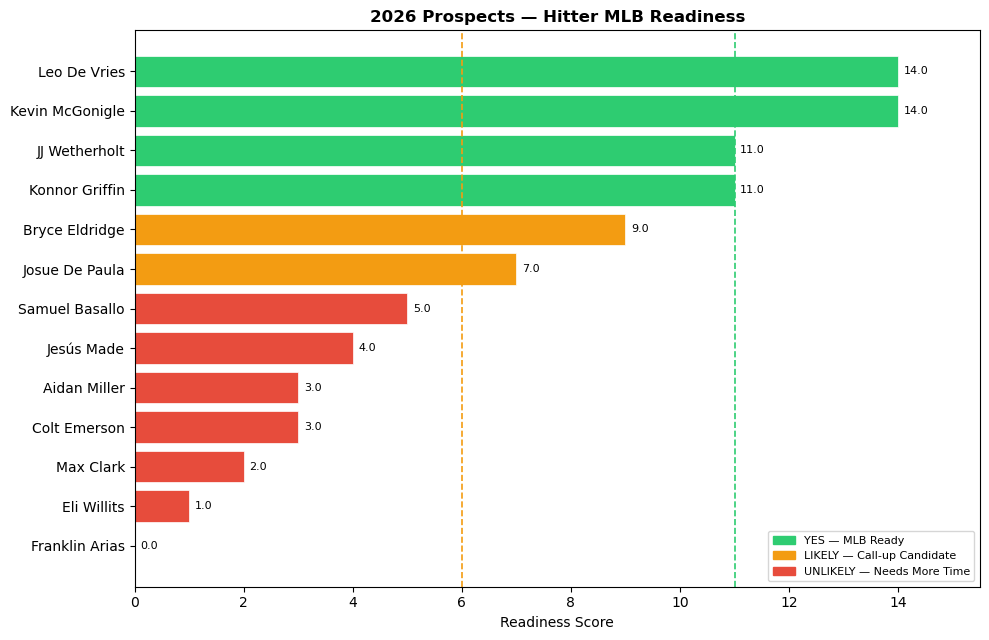

Chart saved.


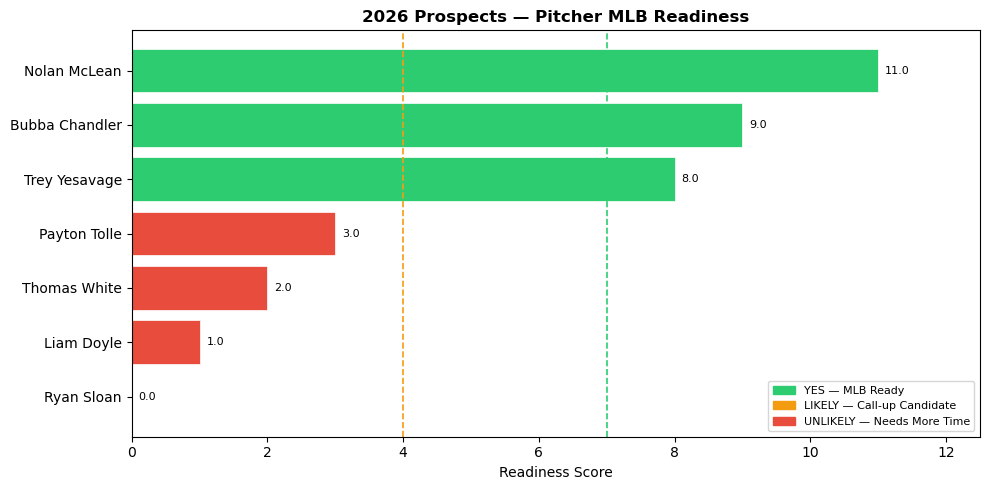

Chart saved.


In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def plot_readiness(df, title, player_type='HITTER'):
    if df.empty or 'Score' not in df.columns:
        print(f'No data for {title}')
        return

    df_sorted = df.sort_values('Score', ascending=True).copy()
    names = df_sorted['Name'].astype(str).tolist()
    scores = df_sorted['Score'].tolist()

    # Color by verdict
    def color_for(s, pt):
        if pt == 'HITTER':
            return '#2ecc71' if s >= 11 else '#f39c12' if s >= 7 else '#e74c3c'
        return '#2ecc71' if s >= 6 else '#f39c12' if s >= 4 else '#e74c3c'

    colors = [color_for(s, player_type) for s in scores]

    fig, ax = plt.subplots(figsize=(10, max(5, len(names) * 0.5)))
    bars = ax.barh(names, scores, color=colors, edgecolor='white', linewidth=0.5)

    for bar, sc in zip(bars, scores):
        ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
                f'{sc:.1f}', va='center', fontsize=8)

    # Threshold lines
    thresh_yes = 11 if player_type == 'HITTER' else 7
    thresh_likely = 6 if player_type == 'HITTER' else 4
    ax.axvline(thresh_yes, color='#2ecc71', linestyle='--', linewidth=1.2, label='MLB Ready')
    ax.axvline(thresh_likely, color='#f39c12', linestyle='--', linewidth=1.2, label='Call-up Candidate')

    green_p = mpatches.Patch(color='#2ecc71', label='YES — MLB Ready')
    orange_p = mpatches.Patch(color='#f39c12', label='LIKELY — Call-up Candidate')
    red_p = mpatches.Patch(color='#e74c3c', label='UNLIKELY — Needs More Time')
    ax.legend(handles=[green_p, orange_p, red_p], loc='lower right', fontsize=8)

    ax.set_xlabel('Readiness Score', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlim(0, max(scores) + 1.5 if scores else 12)
    plt.tight_layout()
    plt.savefig(f"readiness_{'hitters' if player_type=='HITTER' else 'pitchers'}.png", dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Chart saved.')

plot_readiness(prospects_2026_h, '2026 Prospects — Hitter MLB Readiness', 'HITTER')
plot_readiness(prospects_2026_p, '2026 Prospects — Pitcher MLB Readiness', 'PITCHER')

## 8. Benchmark Context: How 2026 Compares to Historical Call-Ups

In [19]:
print('HITTER BENCHMARKS — Comparison Context')
print(f'{"Stat":<8} {"p25":>8} {"Median":>8} {"p75":>8}  (from 2017-2025 MLB-reaching hitters)')
print('-' * 50)
for stat, vals in hitter_benchmarks.items():
    print(f"{stat:<8} {vals['p25']:>8.3f} {vals['median']:>8.3f} {vals['p75']:>8.3f}")

print()
print('PITCHER BENCHMARKS — Comparison Context')
print(f'{"Stat":<8} {"p25":>8} {"Median":>8} {"p75":>8}  (from 2017-2025 MLB-reaching pitchers)')
print('-' * 50)
for stat, vals in pitcher_benchmarks.items():
    print(f"{stat:<8} {vals['p25']:>8.3f} {vals['median']:>8.3f} {vals['p75']:>8.3f}")

HITTER BENCHMARKS — Comparison Context
Stat          p25   Median      p75  (from 2017-2025 MLB-reaching hitters)
--------------------------------------------------
AVG         0.233    0.254    0.269
OBP         0.300    0.318    0.337
SLG         0.378    0.424    0.462
OPS         0.685    0.750    0.799
FV         60.000   60.000   63.750

PITCHER BENCHMARKS — Comparison Context
Stat          p25   Median      p75  (from 2017-2025 MLB-reaching pitchers)
--------------------------------------------------
ERA         3.748    4.205    4.700
WHIP        1.208    1.326    1.449
FV         60.000   60.000   60.000


## 9. Important Notes & Limitations

### Data Quality Flags
- **Spring Training stats** are small-sample and inherently noisy. They are down-weighted 30% in the scoring model.
- **Minor league stats** do not directly translate to MLB production. A .300 hitter in AA is not the same as a .300 MLB hitter.
- Several 2026 prospects with only spring training stats have **fewer than 40 PA**, which makes any rate stats highly unreliable.

### Scoring Model Interpretation
| Verdict | Meaning |
|---|---|
| **YES — MLB Ready** | Stats and profile match or exceed historical call-up benchmarks |
| **LIKELY — Call-up Candidate** | Strong profile, may debut mid-season or after roster moves |
| **UNLIKELY — Needs More Time** | Stats, age, or level suggest 2027+ is more realistic |

### Key Variables the Model Considers
1. **OPS / OBP / SLG / AVG** — rate stats benchmarked against historical call-ups
2. **ERA / WHIP** — pitcher efficiency metrics
3. **Current Level** — MLB/AAA players receive bonus points for proximity
4. **ETA** — organizational official timeline; ETA > 2026 triggers a penalty
5. **Stats_Source** — spring training / minor league stats are discounted

## 10. Quick Summary Table

In [22]:
def summary_table(df, player_type):
    if df.empty or 'Verdict' not in df.columns:
        return
    cols = ['Name', 'Org', 'Pos', 'Score', 'Verdict']
    avail = [c for c in cols if c in df.columns]
    print(f'\n── {player_type} SUMMARY ──')
    out = df[avail].sort_values('Score', ascending=False)
    print(out.to_string(index=False))

summary_table(prospects_2026_h, 'HITTERS')
summary_table(prospects_2026_p, 'PITCHERS')


── HITTERS SUMMARY ──
           Name Org Pos  Score                    Verdict
Kevin McGonigle DET  3B 14.000            YES — MLB Ready
   Leo De Vries ATH  SS 14.000            YES — MLB Ready
 Konnor Griffin PIT  SS 11.000            YES — MLB Ready
  JJ Wetherholt STL  2B 11.000            YES — MLB Ready
 Bryce Eldridge SFG  1B  9.000 LIKELY — Call-up Candidate
 Josue De Paula LAD  RF  7.000 LIKELY — Call-up Candidate
 Samuel Basallo BAL   C  5.000 UNLIKELY — Needs More Time
     Jesús Made MIL  SS  4.000 UNLIKELY — Needs More Time
   Colt Emerson SEA  SS  3.000 UNLIKELY — Needs More Time
   Aidan Miller PHI  SS  3.000 UNLIKELY — Needs More Time
      Max Clark DET  CF  2.000 UNLIKELY — Needs More Time
    Eli Willits WSN  SS  1.000 UNLIKELY — Needs More Time
 Franklin Arias BOS  SS  0.000 UNLIKELY — Needs More Time

── PITCHERS SUMMARY ──
          Name Org Pos  Score                    Verdict
  Nolan McLean NYM  SP 11.000            YES — MLB Ready
Bubba Chandler PIT  SP  9.0